In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
data = {
    'review': [
        'This product is amazing',
        'I love this product',
        'Very good quality',
        'This product is terrible',
        'I hate this product',
        'Very bad quality',
        'It is okay',
        'Nothing special',
        'Average product'
    ],
    'sentiment': [
        'Positive', 'Positive', 'Positive',
        'Negative', 'Negative', 'Negative',
        'Neutral', 'Neutral', 'Neutral'
    ]
}

df = pd.DataFrame(data)
df.head(9)

,review,sentiment
0,This product is amazing,Positive
1,I love this product,Positive
2,Very good quality,Positive
3,This product is terrible,Negative
4,I hate this product,Negative
5,Very bad quality,Negative
6,It is okay,Neutral
7,Nothing special,Neutral
8,Average product,Neutral


In [ ]:
df['sentiment'].value_counts()

,count
sentiment,
Positive,3
Negative,3
Neutral,3


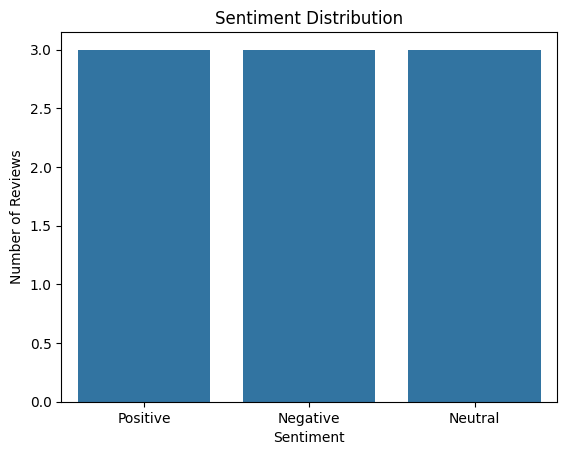

In [ ]:
sns.countplot(x='sentiment', data=df)
plt.title('Sentiment Distribution')
plt.xlabel('Sentiment')
plt.ylabel('Number of Reviews')
plt.show()

In [ ]:
import re

def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', '', text)
    return text

df['cleaned_review'] = df['review'].apply(clean_text)

df[['review', 'cleaned_review']]

,review,cleaned_review
0,This product is amazing,this product is amazing
1,I love this product,i love this product
2,Very good quality,very good quality
3,This product is terrible,this product is terrible
4,I hate this product,i hate this product
5,Very bad quality,very bad quality
6,It is okay,it is okay
7,Nothing special,nothing special
8,Average product,average product


In [ ]:
sentiment_mapping = {
    'Positive': 1,
    'Neutral': 0,
    'Negative': -1
}

df['sentiment_score'] = df['sentiment'].map(sentiment_mapping)

df[['review', 'sentiment', 'sentiment_score']]

,review,sentiment,sentiment_score
0,This product is amazing,Positive,1
1,I love this product,Positive,1
2,Very good quality,Positive,1
3,This product is terrible,Negative,-1
4,I hate this product,Negative,-1
5,Very bad quality,Negative,-1
6,It is okay,Neutral,0
7,Nothing special,Neutral,0
8,Average product,Neutral,0


In [ ]:
from collections import Counter

all_words = ' '.join(df['cleaned_review']).split()

word_counts = Counter(all_words)

word_counts.most_common(10)

[('product', 5),
 ('this', 4),
 ('is', 3),
 ('i', 2),
 ('very', 2),
 ('quality', 2),
 ('amazing', 1),
 ('love', 1),
 ('good', 1),
 ('terrible', 1)]

In [ ]:
sentiment_percentage = df['sentiment'].value_counts(normalize=True) * 100

sentiment_percentage

,proportion
sentiment,
Positive,33.333333
Negative,33.333333
Neutral,33.333333


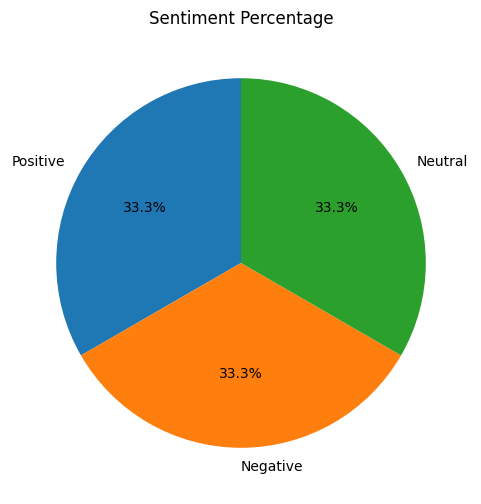

In [ ]:
plt.figure(figsize=(6,6))

plt.pie(
    sentiment_percentage,
    labels=sentiment_percentage.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Sentiment Percentage')
plt.show()

In [ ]:
new_review = "This product is amazing and I love it"

cleaned = clean_text(new_review)

words = cleaned.split()

positive_words = ['amazing', 'love', 'good', 'great', 'excellent']
negative_words = ['terrible', 'hate', 'bad', 'worst', 'poor']

score = sum(1 for word in words if word in positive_words) - sum(1 for word in words if word in negative_words)

if score > 0:
    result = 'Positive'
elif score < 0:
    result = 'Negative'
else:
    result = 'Neutral'

print("Review:", new_review)
print("Sentiment:", result)

Review: This product is amazing and I love it
Sentiment: Positive


In [ ]:
url = 'https://huggingface.co/datasets/Cleanlab/amazon-reviews/resolve/main/train.csv'

amazon_df = pd.read_csv(url)

amazon_df.head()

,review_text,label
0,Excellent product! I love reading through the ...,positive
1,"If you into gaming, into the latest PC tech in...",positive
2,Great Mag..!!,positive
3,"Extremely similar to GQ, same publisher. You a...",positive
4,it is great read and great ideas for today's m...,positive


In [ ]:
amazon_df.shape

(5000, 2)

In [ ]:
amazon_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   review_text  5000 non-null   object
 1   label        5000 non-null   object
dtypes: object(2)
memory usage: 78.3+ KB


In [ ]:
amazon_df['label'].value_counts()

,count
label,
positive,3092
negative,1908


In [ ]:
amazon_df['label'].value_counts(normalize=True) * 100

,proportion
label,
positive,61.84
negative,38.16


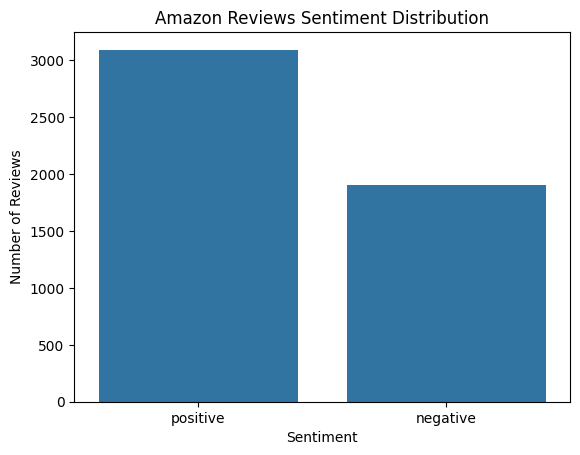

In [ ]:
sns.countplot(data=amazon_df, x='label')
plt.title('Amazon Reviews Sentiment Distribution')
plt.xlabel('Sentiment')
plt.ylabel('Number of Reviews')
plt.show()

In [ ]:
amazon_df.head()

,review_text,label
0,Excellent product! I love reading through the ...,positive
1,"If you into gaming, into the latest PC tech in...",positive
2,Great Mag..!!,positive
3,"Extremely similar to GQ, same publisher. You a...",positive
4,it is great read and great ideas for today's m...,positive


In [ ]:
import re

def clean_review(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', '', text)
    return text

amazon_df['cleaned_review'] = amazon_df['review_text'].apply(clean_review)

amazon_df[['review_text', 'cleaned_review']].head()

,review_text,cleaned_review
0,Excellent product! I love reading through the ...,excellent product i love reading through the m...
1,"If you into gaming, into the latest PC tech in...",if you into gaming into the latest pc tech inf...
2,Great Mag..!!,great mag
3,"Extremely similar to GQ, same publisher. You a...",extremely similar to gq same publisher you are...
4,it is great read and great ideas for today's m...,it is great read and great ideas for todays me...


In [ ]:
from collections import Counter

positive_words = ' '.join(
    amazon_df[amazon_df['label'] == 'positive']['cleaned_review']
).split()

negative_words = ' '.join(
    amazon_df[amazon_df['label'] == 'negative']['cleaned_review']
).split()

print("Positive words:")
print(Counter(positive_words).most_common(15))

print("\nNegative words:")
print(Counter(negative_words).most_common(15))

Positive words:
[('the', 1865), ('i', 1744), ('and', 1626), ('magazine', 1538), ('to', 1279), ('it', 1253), ('this', 1245), ('a', 1084), ('for', 1008), ('love', 870), ('of', 867), ('my', 863), ('is', 747), ('great', 737), ('in', 455)]

Negative words:
[('i', 1487), ('the', 1174), ('to', 962), ('not', 837), ('it', 831), ('and', 719), ('a', 658), ('magazine', 625), ('this', 615), ('for', 487), ('of', 478), ('is', 449), ('my', 435), ('have', 345), ('was', 283)]


In [ ]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

def remove_stopwords(text):
    words = text.split()
    words = [word for word in words if word not in ENGLISH_STOP_WORDS]
    return ' '.join(words)

amazon_df['cleaned_review'] = amazon_df['cleaned_review'].apply(remove_stopwords)

amazon_df[['review_text', 'cleaned_review']].head()

,review_text,cleaned_review
0,Excellent product! I love reading through the ...,excellent product love reading magazine learni...
1,"If you into gaming, into the latest PC tech in...",gaming latest pc tech info like reviews hardwa...
2,Great Mag..!!,great mag
3,"Extremely similar to GQ, same publisher. You a...",extremely similar gq publisher arent going mag...
4,it is great read and great ideas for today's m...,great read great ideas todays men great price ...


In [ ]:
from sklearn.model_selection import train_test_split

X = amazon_df['cleaned_review']
y = amazon_df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", len(X_train))
print("Testing data:", len(X_test))

Training data: 4000
Testing data: 1000


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

model = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=5000, ngram_range=(1, 2))),
    ('classifier', LogisticRegression(max_iter=1000))
])

In [ ]:
model.fit(X_train, y_train)

Pipeline(steps=[('tfidf',
                 TfidfVectorizer(max_features=5000, ngram_range=(1, 2))),
                ('classifier', LogisticRegression(max_iter=1000))])

In [ ]:
y_pred = model.predict(X_test)

In [ ]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

Model Accuracy: 82.19999999999999 %


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

    negative       0.78      0.74      0.76       382
    positive       0.84      0.87      0.86       618

    accuracy                           0.82      1000
   macro avg       0.81      0.81      0.81      1000
weighted avg       0.82      0.82      0.82      1000



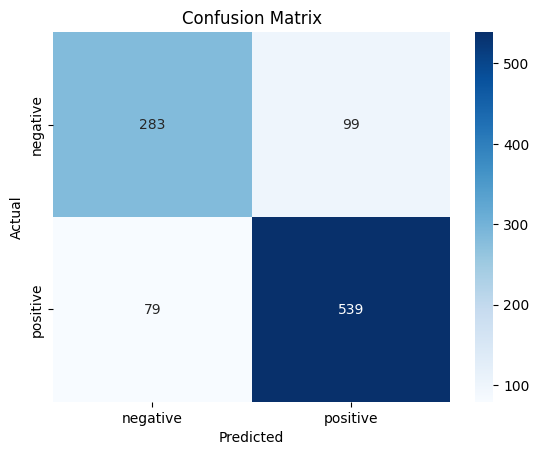

In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred, labels=['negative', 'positive'])

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['negative', 'positive'],
    yticklabels=['negative', 'positive']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [ ]:
new_reviews = [
    "This product is amazing and I love it",
    "Very bad quality, I hate this product",
    "The product is okay, nothing special"
]

predictions = model.predict(new_reviews)

for review, sentiment in zip(new_reviews, predictions):
    print("Review:", review)
    print("Sentiment:", sentiment)
    print("--------------------")

Review: This product is amazing and I love it
Sentiment: positive
--------------------
Review: Very bad quality, I hate this product
Sentiment: negative
--------------------
Review: The product is okay, nothing special
Sentiment: negative
--------------------


Sentiment Analysis of Amazon Product Reviews

Project Overview

This project aims to analyze Amazon product reviews and classify them into positive and negative sentiments using Machine Learning.

Dataset

- 5,000 Amazon reviews.
- 3,092 positive reviews.
- 1,908 negative reviews.

Model

TF-IDF with Logistic Regression.

Accuracy

82.2%

Results and Findings

- The model achieved 82.2% accuracy.
- The model performed better in classifying positive reviews.
- Positive reviews were more common than negative reviews.
- The model successfully predicted sentiments for new reviews.

Conclusion

This project demonstrates how Machine Learning can be used to analyze customer opinions and classify product reviews into positive and negative sentiments. The results show that TF-IDF and Logistic Regression can provide good performance for sentiment analysis.

Limitations

The dataset contains only 5,000 reviews and includes only positive and negative labels. Therefore, the model may not perform equally well on all types of customer reviews.